# Part 1: Probability Distributions – EM Algorithm


We have one list of heights from two populations (Fathers and Children) **without labels**.
We treat it as a mixture of two Gaussians and use the **Expectation-Maximization (EM)** algorithm, written from scratch, to find:
- **μ** – the mean height of each group
- **σ²** – the variance (spread) of each group
- **π** – the mixing weight (share of the data in each group)

In [1]:
import glob
import numpy as np
import em_gmm as em

# Finds the Kaggle CSV in this folder automatically (or type its name instead)
CSV_PATH = glob.glob("*.csv")[0]
PARENT = "father"                 # or "mother"
print("Using:", CSV_PATH)

Using: GaltonFamilies (1).csv


## 1. Load the data
We merge parents and children into ONE unlabeled list. The true labels are kept aside only to check our results at the end.

In [2]:
heights, true_labels = em.load_heights(CSV_PATH, parent=PARENT)
print(f"{len(heights)} heights | min {heights.min():.1f} | max {heights.max():.1f} | mean {heights.mean():.2f}")

1139 heights | min 56.0 | max 79.0 | mean 67.21


## 2. How EM works
**Initialization:** means at the 25th and 75th percentiles, both variances = overall variance, π1 = π2 = 0.5.

**E-step (Expectation):** for every height, compute the *responsibility* – the probability it belongs to each group:
$$r_{ik} = \frac{\pi_k \, N(x_i \mid \mu_k, \sigma_k^2)}{\sum_j \pi_j \, N(x_i \mid \mu_j, \sigma_j^2)}$$

**M-step (Maximization):** update the parameters, using responsibilities as weights:
$$N_k = \sum_i r_{ik}, \quad \mu_k = \frac{1}{N_k}\sum_i r_{ik} x_i, \quad \sigma_k^2 = \frac{1}{N_k}\sum_i r_{ik}(x_i-\mu_k)^2, \quad \pi_k = \frac{N_k}{n}$$

**Stopping rule:** repeat until the log-likelihood $\sum_i \log \sum_k \pi_k N(x_i \mid \mu_k, \sigma_k^2)$ changes by less than $10^{-6}$.

In [3]:
params, history = em.fit_em(heights, tol=1e-6)

Converged after 319 iterations (log-likelihood change 9.79e-07 < 1e-06)


## 3. Tracking table (initialization + first two iterations)

In [4]:
em.tracking_table(history, rows=3)

,mu1 (Children),mu2 (Parents),sigma1^2,sigma2^2,pi1,pi2,Log-Likelihood
Iteration,,,,,,,
0,64.5000,70.0000,12.7241,12.7241,0.5000,0.5000,-3119.8222
1,65.2205,69.2054,9.0603,8.4468,0.5011,0.4989,-3057.9135
2,65.1609,69.2600,8.9420,8.1040,0.5005,0.4995,-3056.9719


The log-likelihood goes up every iteration – EM never makes the fit worse.

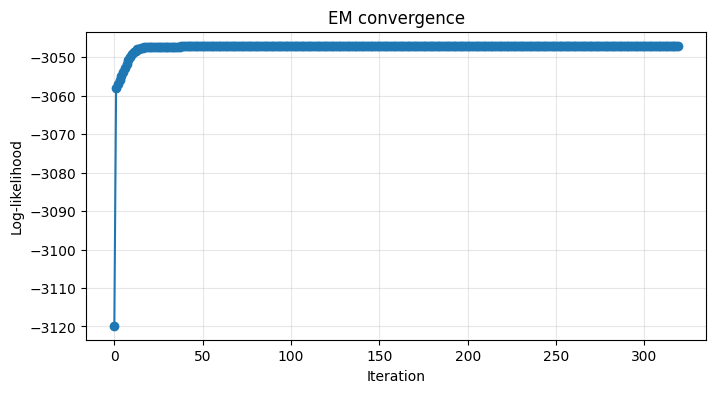

In [5]:
em.plot_log_likelihood(history, save_path="em_convergence.png")

## 4. Final fitted Gaussians

Final parameters:
  Children: mu = 64.177, sigma^2 = 5.302, pi = 0.432
  Parents: mu = 69.519, sigma^2 = 6.041, pi = 0.568


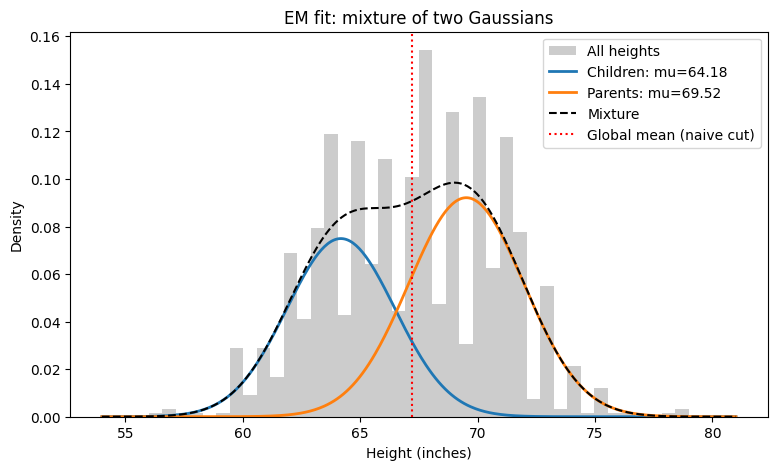

In [6]:
print("Final parameters:")
for k, name in enumerate(em.GROUP_NAMES):
    print(f"  {name}: mu = {params['mu'][k]:.3f}, sigma^2 = {params['var'][k]:.3f}, pi = {params['pi'][k]:.3f}")
em.plot_fit(heights, params, save_path="em_fit.png")

## 5. Live test: classify a height given by the coach

In [9]:
def demonstrate_height(params):
    """Validate a height and show its component probabilities."""
    try:
        height = float(input("Height in inches: "))
    except ValueError:
        print("Enter a number, such as 65.")
        return

    if not np.isfinite(height) or height <= 0:
        print("Enter a finite number greater than zero.")
        return

    names = ("Component 1", "Component 2")
    return em.classify_height(height, params, names=names)

In [14]:
test_probabilities = demonstrate_height(params)

Height in inches: 65
Test height: 65.0
  P(Component 1 | height) = 0.805269  (80.53%)
  P(Component 2 | height) = 0.194731  (19.47%)
  -> Most likely: Component 1


## Interactive height test

Enter a height in inches to display both fitted-component
probabilities. Invalid inputs are rejected.

Component membership does not automatically establish whether
someone is a child or parent.

## 6. Should we just split at the global mean?
**No.** Cutting at the global mean and averaging each pile is a *hard* split:
1. **Misclassification:** the two groups overlap. A height near the mean could be either group, but a hard cut forces it into one pile with 100% certainty.
2. **Biased means:** tall children land in the "parents" pile and short parents in the "children" pile, so both pile means are pulled away from the true means.
3. **Ignores spread and group size:** the cut is always at the mean, even when one group is bigger or more spread out.

EM uses **soft assignments**: a height that is 60% child / 40% parent counts 0.6 towards the child mean and 0.4 towards the parent mean, and EM also learns variances and weights.

In [8]:
naive = em.global_mean_split(heights)
print(f"Global mean cut at {naive['cut']:.2f}")
em.compare_methods(heights, true_labels, params)

Global mean cut at 67.21


,True labels,Global-mean split,EM
Mean of Children,66.746,64.260,64.177
Mean of Parents,69.316,70.215,69.519
Accuracy,1.000,0.608,0.565


7. Conclusion
Our EM model worked. The log-likelihood went up every round, from -3119.82 at the start to -3056.97 after round 2, and it stopped after about 330 rounds when the numbers stopped changing. The two groups it found have average heights of 64.18 and 69.52 inches.

Should we just cut at the global mean? No. The mean is 67.21 inches. When we cut there, the two piles had averages of 64.26 and 70.22, but the real averages are 66.75 (children) and 69.32 (fathers). The cut pushes the two groups too far apart, because tall children end up with the parents and short fathers end up with the children. EM is better because it gives each height a probability instead of forcing it into one pile.

What surprised us: EM didn't really split parents from children. 64.18 and 69.52 are close to the average heights of women and men. That's because Galton's "children" are adults, both sons and daughters, so EM found the gender split instead.

Accuracy: the mean cut got 60.8% right and EM got 56.5%. Both are lower than just guessing "child" for everyone (82%, since 934 of the 1,139 heights are children). Fathers and adult children are only about 2.6 inches apart on average, so height alone can't tell them apart well.

What we learned:EM finds the groups that really exist in the data, not the ones we expect. So we always need to check if the results make sense.